In [84]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# T2 and T2* simulations
 
In this notebook, we will simulate the T2 Hahn and T2* Ramsey characterization protocols with our robust pulses and compare them with the defualt pulses.

# Activate IBM credentials

In [85]:
from qiskit_ibm_provider import IBMProvider

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
provider = IBMProvider(token=IBM_TOKEN, instance="ibm-q-ornl/ornl/phy147")

Get backend and backend configuration

In [138]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.Fake127QPulseV1()
backend = provider.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225#  dt
desired_duration = 120  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

In [139]:
timing = qk_e.framework.BackendTiming(backend)
# timing.pulse_time(samples=len(pico_a[0]))
timing.pulse_time(time=GATE_TIME_SI_UNITS)

6.000000000000001e-08

In [140]:
backend.configuration().dt * ns

0.5

# Pairwise gate simulation
-----

## Custom pulses

### Load from PICO

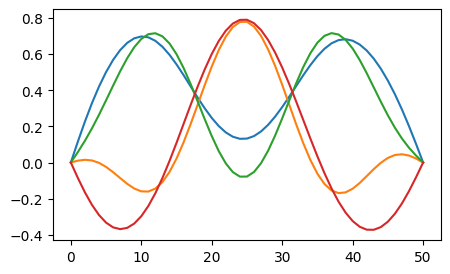

In [141]:
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
)
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

### Symbolic gates (interpolate with splines)

In [142]:
def gateset_from_pico(duration, dt, pico_arr, keys, amp=1.0, angle=0.0):
    assert pico_arr.shape[0] == len(keys)

    gate_lookup = {}

    samples = pico_arr.shape[1]
    for k, row in zip(keys, pico_arr):
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(samples, row, dt=dt))
        )
        gate_lookup[k] = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp, angle=angle
        )

    return gate_lookup

In [143]:
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2"], pico_a)}

### Default gates (gaussians)

In [144]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
}

# Simulation model 
---

We define the model and solver we are going to use for all our simulations.

In [167]:
registers = [0]

config_vars = ps.backend_simulation_vars(backend, rabi=True, units=Units)
carriers = ps.backend_carriers(backend, config_vars)

H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=config_vars,
    rotating_frame=True,
)

A_decay = functools.partial(
    ps.qubit_decay_model, registers=registers, variables=config_vars
)

H_xtalk = ps.crosstalk_model(registers, ps.backend_edges(backend), config_vars)

H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel
    As_static += Ajs_static

In [275]:
solver = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    static_dissipators=As_static,
    hamiltonian_channels=Hs_channels,
    channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
    dt=dt,
)

# T2 Hahn Characterization
----

The experiment is designed following [this](https://qiskit-extensions.github.io/qiskit-experiments/manuals/characterization/t2hahn.html) and [this](https://github.com/Qiskit/textbook/blob/main/notebooks/quantum-hardware-pulses/calibrating-qubits-pulse.ipynb) tutorials.

In [276]:
conversion_factor = 1.0e-6 # our delay will be in micro-sec
delays = list(range(1, 50, 1))
delays = [float(_) * conversion_factor for _ in delays]

We first load the pulses we are going to use, and the calibrations we got from other notebooks. The rough calibrated amplitudes for our robust x/sx pulses are:

```console
x1_rough_amp = 0.23258708831041688
sx1_rough_amp = 0.13940815709074902
x2_rough_amp = 0.6974139812807811
sx2_rough_amp = 0.6963318360927053
```


In [277]:
sx_signal = pico_gates["sx1"]
sx_amp = 0.13940815709074902

sx_signal_samples = ps.resample(
        duration, ps.get_samples(ps.custom_envelope(len(sx_signal), sx_signal, dt=dt))
    )
sx_gate = ps.scalable_symbolic_pulse(
    duration, sx_signal_samples, "sx", amp=sx_amp
)

In [278]:
x_signal = pico_gates["x1"]
x_amp = 0.23258708831041688

x_signal_samples = ps.resample(
        duration, ps.get_samples(ps.custom_envelope(len(x_signal), x_signal, dt=dt))
    )
x_gate = ps.scalable_symbolic_pulse(
    duration, x_signal_samples, "x", amp=x_amp
)

We create a parametrized schedule.

In [279]:
qubit = 0
delay = qk.circuit.Parameter('delay')
with qk.pulse.build(backend=backend, default_alignment='sequential', name="T2 delay Experiment") as t2_schedule:
    drive_chan = qk.pulse.drive_channel(qubit)
    qk.pulse.play(sx_gate, qk.pulse.DriveChannel(qubit))
    qk.pulse.delay(delay, drive_chan)
    qk.pulse.play(x_gate, qk.pulse.DriveChannel(qubit))
    qk.pulse.delay(delay, drive_chan)
    qk.pulse.play(sx_gate, qk.pulse.DriveChannel(qubit))

And we create all the schedules we are going to run in our experiment.

In [280]:
acquire_alignment = backend.configuration().timing_constraints['acquire_alignment']
pulse_alignment = backend.configuration().timing_constraints['pulse_alignment']
original_dt = backend.configuration().dt

lcm = np.lcm(acquire_alignment, pulse_alignment)
def get_closest_multiple_of(value, base_number):
    return int(value + base_number/2) - (int(value + base_number/2) % base_number)

def get_dt_from(sec):
    return get_closest_multiple_of(sec/original_dt, lcm)

In [281]:
exp_t2_scheds = [t2_schedule.assign_parameters({delay: get_dt_from(d)}, inplace=False) for d in delays]

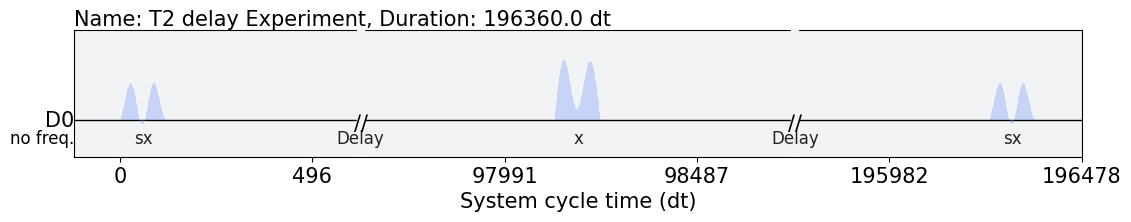

In [282]:
exp_t2_scheds[-1].draw()

In [288]:
max_duration = exp_t2_scheds[-1].duration

We now use the solver to run the experiment.

In [289]:
def prob_meas_0(dm):
    proj = np.array([[1, 0], [0, 0]])
    return np.real(np.trace(dm @ proj))

In [290]:
psi0 = ps.qiskit_ground_state(len(registers))

# Vmap of the rabi calibrations
solver.model.evaluation_mode = "sparse"
solns = solver.solve(
    t_span=[0.0, max_duration],
    t_eval=[max_duration],
    y0=psi0,
    signals=exp_t2_scheds,
    atol=1e-16,
    rtol=1e-16,
    method="jax_odeint",
)

data = np.array([prob_meas_0(s.y[-1].data) for s in solns])
# data = np.array([np.abs(s.y[-1][0]) ** 2 for s in solns])

/Users/epelaezc/Desktop/Research/pulse-simulator/.venv/lib/python3.11/site-packages/qiskit_dynamics/solvers/solver_classes.py:525: UserWarning: Attempting to internally JAX-compile simulation of schedules, with Solver.model.array_library not in ["numpy", "jax", "jax_sparse"]. If an error is not raised, explicitly set array_library at Solver instantation to one of these options to remove this warning.
  warn(


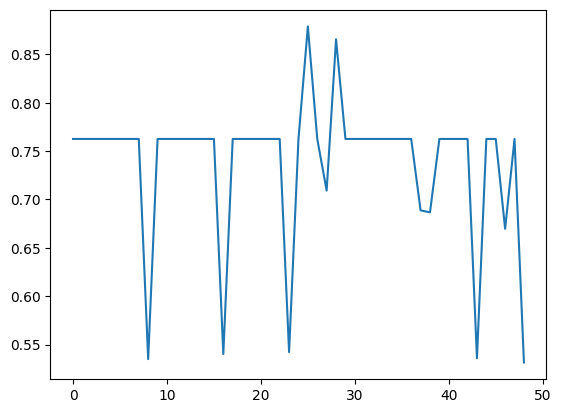

In [292]:
plt.plot(data)